## TH 5.1

Dựng tam giác Pascal $10$ hàng trong ma trận số nguyên $10\times10$ bằng *slicing* (mỗi hàng tính từ hàng trước bằng một phép cộng vector, không dùng vòng lặp lồng): $P_{i,j}=P_{i-1,j}+P_{i-1,j-1}$, $P_{i,0}=1$. In hàng $4$ và hàng $9$; kiểm tra $\binom94=126$ và tổng hàng $9$ bằng $2^9$.

In [14]:
import numpy as np

P = np.zeros((10, 10), dtype=int)

P[0, 0] = 1

for i in range(1, 10):
    P[i, 0] = 1
    P[i, i] = 1

    P[i, 1:i] = P[i-1, 0:i-1] + P[i-1, 1:i]

print("Hàng 4:", P[4, :5])
print("Hàng 9:", P[9, :10])

print("C(9,4) =", P[9, 4])
print("Tổng hàng 9 =", np.sum(P[9, :]))

Hàng 4: [1 4 6 4 1]
Hàng 9: [  1   9  36  84 126 126  84  36   9   1]
C(9,4) = 126
Tổng hàng 9 = 512


## TH 5.6

Cho $A=\begin{pmatrix}2&1&-1&0
1&3&2&1
0&-1&4&2
3&0&1&5\end{pmatrix}$ và véc tơ nghiệm biết trước $\mathbf x^*=(1,-1,2,3)^\top$. Đặt $\mathbf b=A\mathbf x^*$, giải lại hệ bằng `np.linalg.solve`, kiểm chứng bằng `np.allclose`. Sau đó thay hàng $4$ của $A$ bằng tổng hàng $1$ và hàng $2$ và ghi lại lỗi của `solve`.

In [20]:
A = np.array([
    [2, 1, -1, 0],
    [1, 3, 2, 1],
    [0, -1, 4, 2],
    [3, 0, 1, 5]
], dtype=float)

x_true = np.array([1, -1, 2, 3])

b = A @ x_true

x = np.linalg.solve(A, b)

print("Nghiệm x =", x)

print("Kiểm tra:", np.allclose(x, x_true))

Nghiệm x = [ 1. -1.  2.  3.]
Kiểm tra: True


In [24]:
A_moi = A.copy()

A_moi[3] = A_moi[0] + A_moi[1]

try:
    x_moi = np.linalg.solve(A_moi, b)
    print("Nghiệm:", x_moi)
except np.linalg.LinAlgError as e:
    print("Lỗi:", e)

Nghiệm: [ 8.40671930e+16 -2.40191980e+16  1.44115188e+17 -3.00239975e+17]


## TH 5.7

Đa thức bậc $3$ đi qua bốn điểm $(0,1)$, $(1,0)$, $(2,5)$, $(3,22)$ là duy nhất. Tìm các hệ số $c_0,…,c_3$ của $p(x)=c_0+c_1x+c_2x^2+c_3x^3$ bằng cách giải hệ với *ma trận Vandermonde* (`np.vander(x, increasing=True)`), kiểm tra bằng `allclose`, rồi tính $p(1{,}5)$.

In [26]:
x = np.array([0, 1, 2, 3])
y = np.array([1, 0, 5, 22])

V = np.vander(x, increasing=True)

c = np.linalg.solve(V, y)

print("Ma trận V:")
print(V)

print("Các hệ số:", c)

# Kiểm tra
print("Kiểm tra:", np.allclose(V @ c, y))

# Tính p(1.5)
t = 1.5
p = c[0] + c[1]*t + c[2]*t**2 + c[3]*t**3

print("p(1.5) =", p)

Ma trận V:
[[ 1  0  0  0]
 [ 1  1  1  1]
 [ 1  2  4  8]
 [ 1  3  9 27]]
Các hệ số: [ 1. -2. -0.  1.]
Kiểm tra: True
p(1.5) = 1.375


## TH 5.8

Với ma trận ngẫu nhiên $500\times500$ (`default_rng(0)`) và véc tơ $\mathbf b$ ngẫu nhiên, giải $A\mathbf x=\mathbf b$ bằng `solve` và bằng `inv(A) @ b`. So sánh *phần dư* $\|A\mathbf x-\mathbf b\|$ và thời gian của hai cách; kiểm tra bằng `assert` cả hai nghiệm đều đạt phần dư rất nhỏ và giống nhau.

In [36]:
import time
rng = np.random.default_rng(0)

A = rng.random((500, 500))
b = rng.random(500)

start = time.time()

x1 = np.linalg.solve(A, b)

time1 = time.time() - start

r1 = np.linalg.norm(A @ x1 - b)


start = time.time()

x2 = np.linalg.inv(A) @ b

time2 = time.time() - start

r2 = np.linalg.norm(A @ x2 - b)

print("Cách 1: phần dư là:")
print("Phần dư:", r1)

print("\nCách 2: phần dư là:")
print("Phần dư:", r2)

assert r1 < 1e-8
assert r2 < 1e-8
assert np.allclose(x1, x2)


Cách 1: phần dư là:
Phần dư: 7.555663501542652e-13

Cách 2: phần dư là:
Phần dư: 2.6747435235167933e-12


## TH 6.2

Viết chương trình nhập danh sách sinh viên (họ tên, mã sinh viên, ngày sinh dạng `dd/mm/yyyy`) từ bàn phím, dừng khi người dùng bỏ trống họ tên (vòng `while True`, Chương \ref{ch:dieukhien}). Lưu vào một `DataFrame`, chuyển ngày sinh sang kiểu thời gian bằng `pd.to_datetime(…, format="%d/%m/%Y")`, tính cột `Tuoi` (số năm nguyên) từ ngày sinh đến mốc $01/01/2026$ (dùng `pd.Timestamp("2026-01-01")`, chia số ngày cho $365{,}25$ rồi lấy phần nguyên), ghi ra `students.xlsx` bằng `to_excel` (cần `openpyxl`) và đọc lại để kiểm tra. Dùng mốc cố định thay cho `pd.Timestamp.now()` để kết quả tái lập được.

In [40]:
import pandas as pd

sv = []

while True:
    name = input("Nhập họ tên: ")

    if name == "":
        break

    msv = input("Nhập mã sinh viên: ")
    sn = input("Nhập ngày sinh (dd/mm/yyyy): ")

    sv.append([name, msv, sn])

df = pd.DataFrame(sv, columns=["Ho_ten", "Ma_sv", "Ngay_sinh"])

df["Ngay_sinh"] = pd.to_datetime(
    df["Ngay_sinh"],
    format="%d/%m/%Y"
)

moc = pd.Timestamp("2026-01-01")

df["Tuoi"] = ((moc - df["Ngay_sinh"]).dt.days // 365.25).astype(int)

print(df)

# Lưu Excel
df.to_excel("sv.xlsx", index=False)

# Đọc lại để kiểm tra
df_check = pd.read_excel("sv.xlsx")

print("\nDữ liệu đọc lại:")
print(df_check)

Nhập họ tên:  Ngọc Ánh
Nhập mã sinh viên:  233030553
Nhập ngày sinh (dd/mm/yyyy):  07/08/2005
Nhập họ tên:  Phương Anh
Nhập mã sinh viên:  233000551
Nhập ngày sinh (dd/mm/yyyy):  24/08/2005
Nhập họ tên:  


       Ho_ten      Ma_sv  Ngay_sinh  Tuoi
0    Ngọc Ánh  233030553 2005-08-07    20
1  Phương Anh  233000551 2005-08-24    20

Dữ liệu đọc lại:
       Ho_ten      Ma_sv  Ngay_sinh  Tuoi
0    Ngọc Ánh  233030553 2005-08-07    20
1  Phương Anh  233000551 2005-08-24    20


## TH 6.3

Với `data/200heightsweights.csv` (chiều cao inch, cân nặng pound của $200$ người): (1) đổi tên cột thành `Height_in`, `Weight_lb`, đổi sang cm và kg, điền ô thiếu bằng trung bình cột, tính `BMI`, viết bằng method chaining; (2) đếm số người có $\mathrm{BMI}<18{,}5$; (3) dùng `pd.cut` chia chiều cao thành ba nhóm: `Thap` ($<170$ cm), `Trung binh` ($[170,175)$), `Cao` ($\ge175$) và đếm số người từng nhóm; (4) dùng `groupby` tính *tỉ lệ* người có $\mathrm{BMI}<18{,}5$ trong từng nhóm (gợi ý: trung bình của một cột logic là tỉ lệ `True`); (5) vẽ boxplot cân nặng theo nhóm chiều cao bằng Seaborn và lưu `box.png`; (6) nếu đã cài `plotly`, vẽ biểu đồ phân tán tương tác chiều cao -- cân nặng, tô màu theo nhóm.

Số người BMI < 18.5: 50

Tỷ lệ BMI < 18.5 theo nhóm:
Nhom
Thap          0.258065
Trung binh    0.234568
Cao           0.263158
Name: BMI_thap, dtype: float64


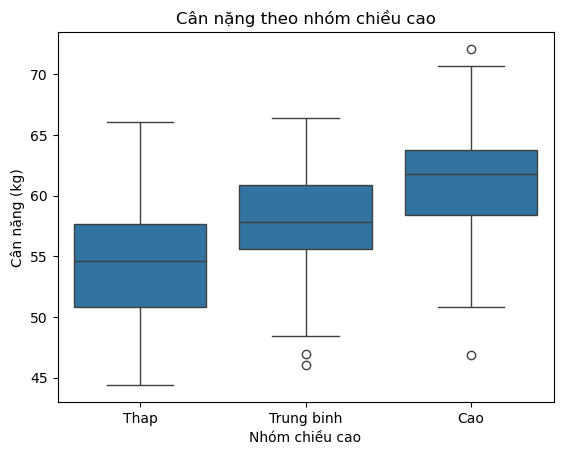

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("200heightsweights.csv")

df = df.rename(columns={
    "Height(Inches)": "Height_in",
    "Weight(Pounds)": "Weight_lb"
})

df["Height_cm"] = df["Height_in"] * 2.54
df["Weight_kg"] = df["Weight_lb"] * 0.453592

df["Height_cm"] = df["Height_cm"].fillna(df["Height_cm"].mean())
df["Weight_kg"] = df["Weight_kg"].fillna(df["Weight_kg"].mean())

df = df.assign(
    BMI=df["Weight_kg"] / (df["Height_cm"] / 100) ** 2
)

print("Số người BMI < 18.5:", (df["BMI"] < 18.5).sum())

df["Nhom"] = pd.cut(
    df["Height_cm"],
    bins=[-np.inf, 170, 175, np.inf],
    labels=["Thap", "Trung binh", "Cao"],
    right=False
)

df["BMI_thap"] = df["BMI"] < 18.5

ty_le = df.groupby("Nhom", observed=False)["BMI_thap"].mean()

print("\nTỷ lệ BMI < 18.5 theo nhóm:")
print(ty_le)

sns.boxplot(data=df, x="Nhom", y="Weight_kg")

plt.xlabel("Nhóm chiều cao")
plt.ylabel("Cân nặng (kg)")
plt.title("Cân nặng theo nhóm chiều cao")

plt.savefig("box.png")
plt.show()

## TH 6.4

Với `data/core_HRdata.csv` (nhân sự; các cột `Department`, `Sex`, `Pay Rate`, `Date of Hire`, `Performance Score`): (1) làm sạch tên phòng ban bằng `.str.strip()` (còn $6$ phòng ban); (2) lập bảng lương trung bình theo phòng ban (hàng) và giới tính (cột) bằng `groupby` và `unstack`; (3) chuyển `Date of Hire` sang kiểu thời gian, tính `Tham_nien` (số năm nguyên đến mốc $01/01/2017$, dùng `.dt.days // 365`) và in $5$ nhân viên có thâm niên cao nhất (sắp theo thâm niên giảm dần, ngang nhau thì theo tên nhân viên tăng dần, bằng `sort_values` với hai khoá); (4) thống kê số nhân viên theo `Performance Score`.

In [48]:
df = pd.read_csv("core_HRdata.csv")

df["Department"] = df["Department"].str.strip()

bang_luong = df.groupby(
    ["Department", "Sex"]
)["Pay Rate"].mean().unstack()

print("Bảng lương trung bình:")
print(bang_luong)

df["Date of Hire"] = pd.to_datetime(df["Date of Hire"])

moc = pd.Timestamp("2017-01-01")

df["Tham_nien"] = (
    (moc - df["Date of Hire"]).dt.days // 365
)

top5 = df.sort_values(
    ["Tham_nien", "Employee Name"],
    ascending=[False, True]
).head(5)

print("\n5 nhân viên có thâm niên cao nhất:")
print(top5[["Employee Name", "Date of Hire", "Tham_nien"]])

print("\nSố nhân viên theo Performance Score:")
print(df["Performance Score"].value_counts())

Bảng lương trung bình:
Sex                      Female       Male
Department                                
Admin Offices         26.160000  40.500000
Executive Office      80.000000        NaN
IT/IS                 42.536316  46.740455
Production            22.613701  23.827284
Sales                 55.683333  55.375000
Software Engineering  52.330000  43.167500

5 nhân viên có thâm niên cao nhất:
        Employee Name Date of Hire  Tham_nien
282  Riordan, Michael   2006-01-09         10
165       Pitt, Brad    2007-11-05          9
254  Thibaud, Kenneth   2007-06-25          9
68       Alagbe,Trina   2008-01-07          8
0          Brown, Mia   2008-10-27          8

Số nhân viên theo Performance Score:
Performance Score
Fully Meets                 172
N/A- too early to review     37
90-day meets                 31
Exceeds                      28
Needs Improvement            15
Exceptional                   9
PIP                           9
Name: count, dtype: int64
